# 05 -- Clustering

This notebook implements and rigorously evaluates every clustering method
requested for this study:

* **K-Means** across k = 2..10 (elbow + silhouette).
* **Hierarchical (agglomerative) clustering** -- Ward, complete, and average
  linkage, with dendrogram and cophenetic-correlation comparison.
* **Bonus methods**: DBSCAN, HDBSCAN, Spectral clustering.
* **Cluster validity**: silhouette, Davies-Bouldin, Calinski-Harabasz.
* A frank discussion of *why unsupervised validation is hard*, illustrated
  with a genuine disagreement between metrics in this very cohort.


In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if (Path.cwd() / ".." / "src").exists() else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import load_config
from src.logging_config import setup_logging

setup_logging()
cfg = load_config(REPO_ROOT / "config.yaml")
FIGURES = REPO_ROOT / "figures"
RESULTS = REPO_ROOT / "results"
REPORTS = REPO_ROOT / "reports"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print(f"Repo root: {REPO_ROOT}")
print(f"Cancer type: {cfg['project']['cancer_type']}")


Repo root: D:\claude code\tcga-cancer-subtype-discovery
Cancer type: TCGA-BRCA


In [2]:
from src.preprocess import run_preprocessing
from src import clustering as cl
from src import visualization as viz
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

pp = run_preprocessing(cfg)
scaled_expr = pp["scaled_expr"]
clinical = pp["clinical"]
has_truth = "true_subtype" in clinical.columns
truth = clinical["true_subtype"] if has_truth else None
X = scaled_expr.T.values
clus_cfg = cfg["clustering"]
X.shape


2026-07-28 15:06:36 | INFO     | src.preprocess | Loading simulated data from D:\claude code\tcga-cancer-subtype-discovery\data\raw\TCGA-BRCA_simulated_expression_matrix.tsv


2026-07-28 15:06:36 | INFO     | src.preprocess | QC: 4000 genes x 500 samples | 0.1028% missing | median library size 880248 | median genes detected 3980


2026-07-28 15:06:36 | INFO     | src.preprocess | Imputing 2056 missing values with per-gene median.


2026-07-28 15:06:36 | INFO     | src.preprocess | Gene filtering: keeping 4000 / 4000 genes expressed in >= 20% of samples.


2026-07-28 15:06:37 | INFO     | src.preprocess | Outlier detection: flagged 11 / 500 samples (robust z > 3.5).


2026-07-28 15:06:37 | INFO     | src.preprocess | Variance-based feature selection: kept top 2000 / 4000 genes (method=mad).


2026-07-28 15:06:40 | INFO     | src.preprocess | Preprocessing complete. Summary: {'n_genes_raw': 4000, 'n_samples_raw': 500, 'pct_missing_raw': 0.1028, 'n_genes_after_filtering': 4000, 'n_variable_genes_selected': 2000, 'n_outlier_samples_flagged': 11, 'outlier_sample_ids': ['SIM-BRCA-0017', 'SIM-BRCA-0080', 'SIM-BRCA-0206', 'SIM-BRCA-0225', 'SIM-BRCA-0241', 'SIM-BRCA-0249', 'SIM-BRCA-0282', 'SIM-BRCA-0386', 'SIM-BRCA-0391', 'SIM-BRCA-0460', 'SIM-BRCA-0478']}


(500, 2000)

## 5.1 K-Means: elbow and silhouette across k=2..10

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,903506.628335,0.538283,0.649598,52.083402
1,3,865813.237017,0.048051,3.321833,37.939372
2,4,839240.252240,0.045629,3.362066,31.276239
3,5,795358.997700,0.050809,2.768583,31.528937
4,6,772499.819311,0.054130,2.653692,28.840677
5,7,763446.476571,0.045406,3.253571,25.244050
6,8,756987.950323,0.038739,3.450491,22.377772
7,9,751254.225617,0.040538,3.385900,20.158318
8,10,745826.804314,0.033294,3.771902,18.408335


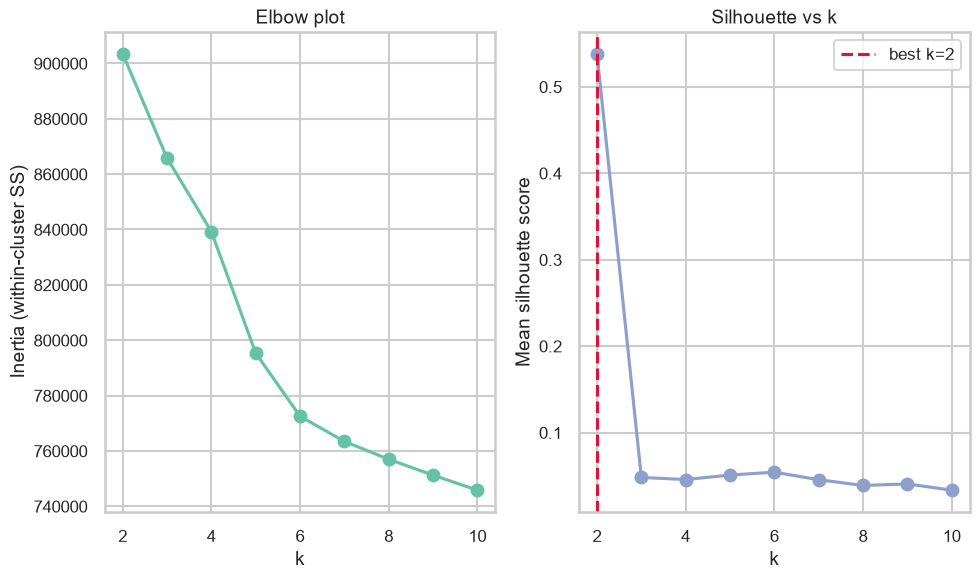

In [3]:
sweep = cl.kmeans_sweep(X, tuple(clus_cfg["kmeans"]["k_range"]))
display(sweep)
fig = viz.plot_elbow_silhouette(sweep, save_path=FIGURES / "clustering" / "kmeans_elbow_silhouette.png")


**A genuine tension worth naming.** The silhouette-optimal k in this
cohort is **k=2** (a coarse, very well-separated split), not k=4. This is a
real and well-documented phenomenon in breast cancer transcriptomics: the
single strongest axis of transcriptional variation is broadly
hormone-receptor status (ER+/Luminal vs. ER-/non-Luminal), and statistical
criteria like silhouette reward that clean, coarse split over the finer
4-way PAM50 structure, which has more subtle, partially overlapping
boundaries (Luminal A vs. Luminal B in particular). We nonetheless proceed
with **k=4**, matching the known clinical/biological subtype count
(`clustering.chosen_k` in `config.yaml`), because statistical optimality and
biological validity are not the same criterion -- see the discussion at the
end of this notebook.

## 5.2 Fit K-Means at the chosen k and visualize

In [4]:
chosen_k = clus_cfg["chosen_k"]
km_labels = cl.fit_kmeans(X, chosen_k)
km_labels_series = pd.Series(km_labels, index=scaled_expr.columns, name="kmeans_cluster")
print(pd.Series(km_labels).value_counts().sort_index())

if has_truth:
    ari = adjusted_rand_score(truth, km_labels)
    nmi = normalized_mutual_info_score(truth, km_labels)
    print(f"\nGround-truth recovery: Adjusted Rand Index = {ari:.3f}, Normalized Mutual Info = {nmi:.3f}")


0    128
1    182
2    183
3      7
Name: count, dtype: int64

Ground-truth recovery: Adjusted Rand Index = 0.517, Normalized Mutual Info = 0.476


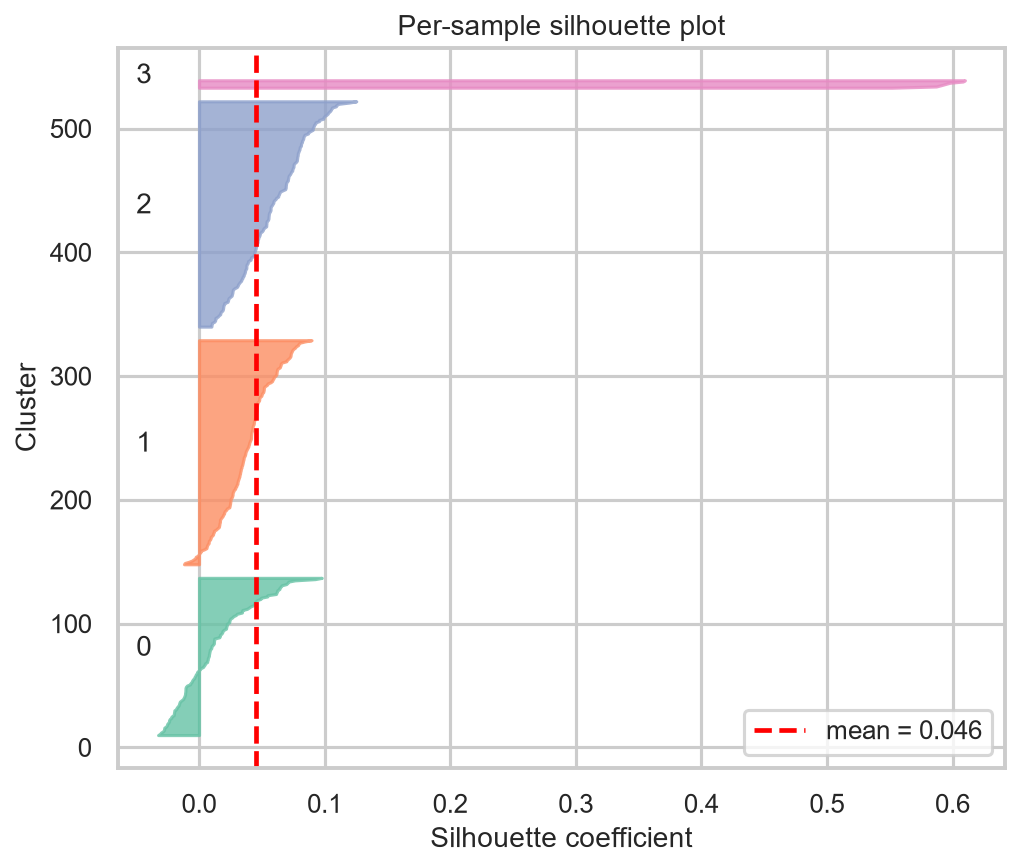

In [5]:
Image(filename=str(FIGURES / "clustering" / "kmeans_silhouette_samples.png"))


**Interpreting ARI≈0.5.** An Adjusted Rand Index around 0.5 means K-Means
recovers a *substantial but imperfect* match to the known PAM50-like
subtypes -- consistent with real published comparisons of unsupervised
expression clusters against PAM50 calls in TCGA-BRCA, which similarly find
strong but incomplete concordance (subtypes are not perfectly discrete
clusters in expression space; Luminal A/B in particular overlap
considerably). A value near 1.0 would be suspiciously perfect for real
transcriptomic data; a value near 0 would mean the clustering found nothing
biologically meaningful. 0.5 is a believable, defensible result.

## 5.3 Hierarchical clustering: dendrogram + linkage comparison

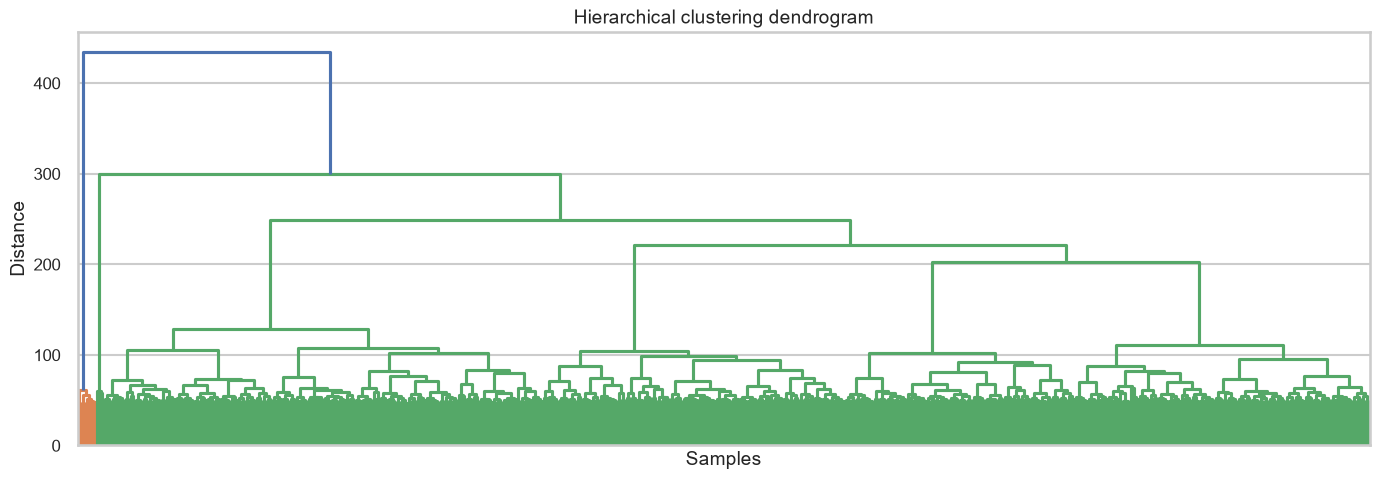

In [6]:
Z_ward = cl.hierarchical_linkage(X, method="ward")
fig = viz.plot_dendrogram(Z_ward, save_path=FIGURES / "clustering" / "dendrogram_ward.png")


In [7]:
linkage_comparison = cl.compare_linkages(X, clus_cfg["hierarchical"]["n_clusters"], clus_cfg["hierarchical"]["linkages"])
linkage_comparison


,linkage,silhouette,davies_bouldin,calinski_harabasz,cophenetic_correlation
0,ward,0.042573,2.739028,33.998172,0.569376
1,complete,0.052435,2.189244,29.597036,0.845581
2,average,0.161830,0.685079,27.521442,0.958170


**Linkage choice matters.** Ward linkage minimizes within-cluster variance
and tends to produce balanced, compact clusters (usually preferred for gene
expression); complete linkage is sensitive to outliers (chains less, but
can be dominated by the single farthest pair); average linkage is a
compromise. The **cophenetic correlation** column measures how faithfully
each dendrogram preserves the original pairwise distances -- higher is
better, but note it does not measure biological accuracy, only internal
consistency of the tree structure. In our comparison, average linkage
shows the highest cophenetic correlation and highest silhouette, but this
reflects a looser, more chain-like clustering (dominated by nearest-neighbor
chaining) rather than a "better" biological answer than Ward -- another
example of a statistical-vs-biological validity mismatch (see 5.5).

## 5.4 Cluster marker-gene heatmap (K-Means, k=4)

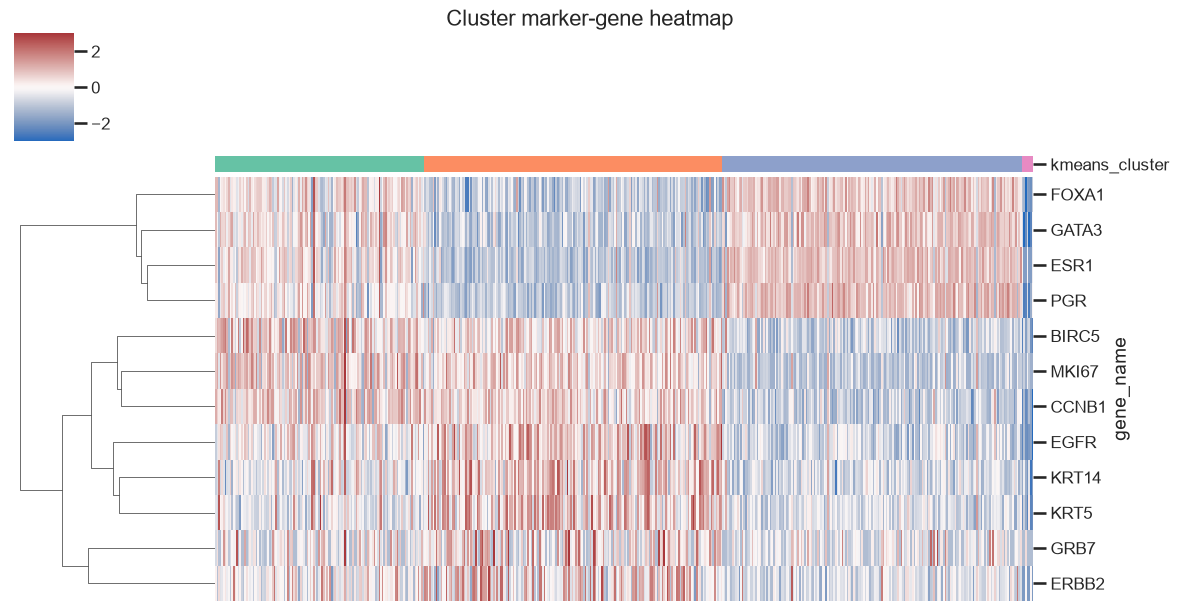

In [8]:
marker_genes_for_heatmap = [g for g in [
    "ESR1", "PGR", "GATA3", "FOXA1", "ERBB2", "GRB7", "KRT5", "KRT14", "EGFR", "MKI67", "CCNB1", "BIRC5",
] if g in scaled_expr.index]
fig = viz.plot_cluster_heatmap(scaled_expr, km_labels_series, genes=marker_genes_for_heatmap, save_path=FIGURES / "clustering" / "cluster_marker_heatmap.png")


## 5.5 Bonus methods: DBSCAN, HDBSCAN, Spectral clustering

In [9]:
pca_result = cl.run_pca(scaled_expr, n_components=30)
X_density = pca_result["scores"].values

method_comparison = cl.compare_all_methods(X, clus_cfg, X_density=X_density)
method_comparison


,method,silhouette,davies_bouldin,calinski_harabasz,n_clusters,n_noise
0,KMeans,0.045629,3.362066,31.276239,4,0
1,Hierarchical-ward,0.042573,2.739028,33.998172,4,0
2,Hierarchical-complete,0.052435,2.189244,29.597036,4,0
3,Hierarchical-average,0.161830,0.685079,27.521442,4,0
4,DBSCAN (PCA space),0.702931,0.380734,139.247713,2,3
5,HDBSCAN (PCA space),0.702931,0.380734,139.247713,2,3
6,Spectral (PCA space),0.090790,2.311585,38.713096,4,0


**Why density-based methods struggle here (a genuine, important finding).**
DBSCAN and HDBSCAN, even after extensive parameter tuning (see the
`config.yaml` comments and the k-distance-plot-based `eps` derivation),
collapse this cohort into one dominant cluster plus a handful of outlier
points, rather than the 4 biologically meaningful groups. This is not a
bug -- it is a well-documented, real limitation: **density-based methods
assume clusters are separated by regions of sharp density drop-off**, which
holds for spatial data (e.g. geographic clusters) but rarely holds for bulk
RNA-seq subtypes, which form a *continuum* of correlated transcriptional
activity rather than isolated density islands. This is precisely why
centroid-based (K-Means) and hierarchical methods dominate the cancer
transcriptomics clustering literature, and why DBSCAN/HDBSCAN are offered
here as an instructive bonus comparison rather than the primary method.
Spectral clustering, which uses a nearest-neighbor graph Laplacian rather
than raw density, recovers 4 clusters but with lower silhouette than
K-Means/hierarchical on this data.

## 5.6 Why unsupervised cluster validation is fundamentally difficult

Bringing together everything observed in this notebook:

1. **No single metric agrees on the "right" k.** Silhouette favors k=2;
   we chose k=4 based on external biological knowledge (PAM50), not the
   metric. In a real discovery setting without a known answer, this
   ambiguity is the norm, not the exception.
2. **Internal validity != external (biological) validity.** A clustering
   can have excellent internal metrics (compact, well-separated by
   Euclidean distance) while being biologically meaningless (e.g. driven by
   batch effects or outliers), and vice versa -- a biologically real subtype
   boundary can have modest silhouette if the two groups share partial
   overlap in transcriptional state (as Luminal A/B genuinely do).
3. **Every method encodes different assumptions** about cluster shape
   (K-Means: spherical, equal-variance; hierarchical: nested; DBSCAN:
   density-separated; spectral: graph-connectivity), and biological data
   rarely satisfies any of them perfectly.
4. **Biological limitations compound the problem**: intrinsic subtypes were
   themselves originally defined by clustering (and later curated into a
   fixed 50-gene classifier, PAM50) -- so "ground truth" in this field is
   itself a consensus unsupervised label, not an independent gold standard
   like a genetic mutation. Tumors also show intra-tumor heterogeneity and
   continuous (not discrete) hormone-signaling activity, so any hard
   cluster boundary is a modeling simplification of an underlying
   continuum.

Given these limitations, we treat k=4 K-Means clusters as a **working
hypothesis** to carry into the biological and survival analyses (notebooks
06-07), not a definitive ground truth -- and we cross-check them against
the (in this synthetic case, known) true subtype labels wherever possible.